# 11 - Sign Language (ASL alphabet) Classification from Photos
**Topic:** Computer Vision  |  **Reference:** "Sign Language Classification with Python" (amanxai.com, Dec 2020)

**Question.** Which of the 26 letters of the American Sign Language alphabet is a person signing in a photo?

**Reference method:** Kaggle "Sign Language MNIST" (28x28 grey-scale pixels, a separate test file), a small Keras network and image augmentation, one accuracy report. (That Kaggle file needs an account; it is not on the public Hugging Face hub in a loadable form, so I use a different public data set below.)
**My data:** 10,873 real **colour photos** of hands (26 classes, about 420 each) with very different backgrounds and sizes, which is a harder, more realistic problem than 28x28 grey pixels.
**What I focus on:** (1) a pretrained network (ResNet-18) used as a **feature extractor** plus a simple classifier, against a CNN trained from scratch; (2) **data leakage**: exactly ~420 images per class hints that the set contains augmented copies of the same original photos, which would put near-identical pictures in both training and test and inflate the score. I test for it and measure how much; (3) which letters get confused; (4) robustness to flips, rotation, brightness and blur.

## 1. Libraries and data

In [1]:
import warnings, os, io, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageEnhance, ImageFilter
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models, transforms
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(8)
os.makedirs("model", exist_ok=True)
df = pd.read_parquet("../_data/asl_hf/data/train-00000-of-00001.parquet")
LET = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"); y = df["label"].to_numpy()
print(df.shape, "| classes:", len(set(y)), "| images per class: min %d, max %d" % (np.bincount(y).min(), np.bincount(y).max()))

(10873, 2) | classes: 26 | images per class: min 380, max 420


## 2. Look at the data first

image width: median 282 (range 119-588) | height: median 269 (range 117-641) | share non-square: 100%


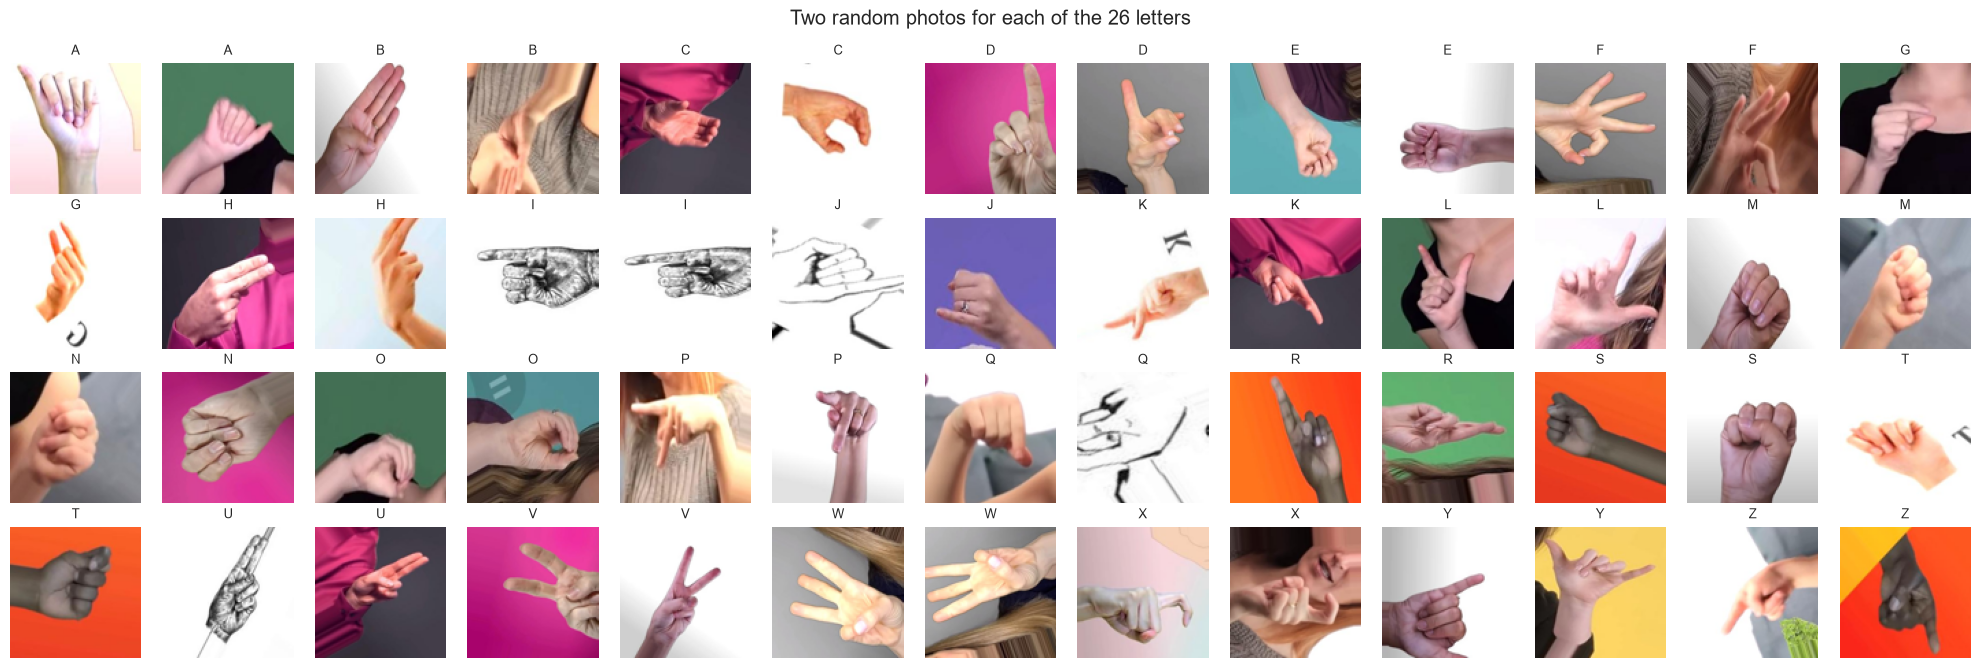

In [2]:
decode = lambda i: Image.open(io.BytesIO(df.iloc[i]["image"]["bytes"])).convert("RGB")
sizes = np.array([decode(i).size for i in range(0, len(df), 10)])
print("image width: median %d (range %d-%d) | height: median %d (range %d-%d) | share non-square: %.0f%%" % (np.median(sizes[:, 0]), sizes[:, 0].min(), sizes[:, 0].max(), np.median(sizes[:, 1]), sizes[:, 1].min(), sizes[:, 1].max(), (sizes[:, 0] != sizes[:, 1]).mean() * 100))
fig, ax = plt.subplots(4, 13, figsize=(20, 6.8))
rs = np.random.RandomState(1)
for k, a in enumerate(ax.ravel()):
    cls = k // 2 if k < 52 else 0; idx = rs.choice(np.where(y == cls)[0]); a.imshow(decode(idx).resize((96, 96))); a.set_title(LET[cls], fontsize=9); a.axis("off")
plt.suptitle("Two random photos for each of the 26 letters"); plt.tight_layout(); plt.show()

**Reading it.** 10,873 colour photos in 26 classes with 380-420 images each (an almost perfectly balanced set, which already hints at augmentation). Image sizes vary widely (median 282 x 269 pixels, ranging from about 120 to 640 per side) and almost none are exactly square, so every image is resized to 224 x 224 for the network. The photos differ in background colour, skin tone, clothing, framing and sharpness, and several letters look alike (A, E, M, N, S and T are all closed fists). This is a much harder setting than the 28 x 28 grey-scale Sign-MNIST in the reference. The data card does not say how the 420-per-class figure came about; I test the possibility of copies below.

## 3. Embed every image with a pretrained ResNet-18
ResNet-18 (ImageNet weights) turns each photo into a 512-number vector; we then train a light classifier on those vectors. Photos are resized to 224x224 (a centre crop is **not** used so that fingers at the edge are kept). The embeddings are cached.

In [3]:
cache = "../_data/asl_resnet18_emb.npz"
tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1); net.fc = nn.Identity(); net.eval()
def embed(imgs, bs=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(imgs), bs): out.append(net(torch.stack([tf(im) for im in imgs[i:i + bs]])).numpy())
    return np.concatenate(out)
if os.path.exists(cache):
    z = np.load(cache); E, thumbs = z["E"], z["thumbs"]
else:
    t = time.time(); E, th = [], []
    for s in range(0, len(df), 512):
        ims = [decode(i) for i in range(s, min(s + 512, len(df)))]; E.append(embed(ims)); th += [np.asarray(im.resize((64, 64))) for im in ims]
    E, thumbs = np.concatenate(E), np.stack(th); np.savez_compressed(cache, E=E, thumbs=thumbs); print("embedding time %.0fs" % (time.time() - t))
print("embeddings", E.shape, "| thumbnails", thumbs.shape)

embeddings (10873, 512) | thumbnails (10873, 64, 64, 3)


## 4. Are there near-duplicate photos? (the leakage test)
Cosine similarity between embeddings; for every image, its most similar *other* image. If the set contains rotated/flipped/recoloured copies of the same photo, many images will have a near-identical twin. Images are then linked when their similarity is above a threshold and the connected components are **groups of near-copies**.

In [4]:
Ec = E - E.mean(0)                                   # centre the features: raw ResNet features are all positive, so every pair looks similar
En = Ec / np.linalg.norm(Ec, axis=1, keepdims=True)
nn_ = NearestNeighbors(n_neighbors=6, metric="cosine").fit(En); dist, ind = nn_.kneighbors(En); sim = 1 - dist[:, 1]       # similarity to nearest OTHER image
same_cls = (y[ind[:, 1]] == y)
print("nearest-neighbour similarity: median %.3f | 10th pct %.3f | 90th pct %.3f" % (np.median(sim), *np.percentile(sim, [10, 90])))
print("nearest other image has the same letter in %.1f%% of cases" % (same_cls.mean() * 100))
def groups_at(T):
    rows, cols = [], []
    for j in range(1, 6):
        m = (1 - dist[:, j]) >= T; rows += list(np.where(m)[0]); cols += list(ind[m, j])
    n, lab = connected_components(csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(En), len(En))), directed=False); return n, lab
tab = []
for T in (0.70, 0.80, 0.85, 0.90):
    n, lab = groups_at(T); sz = np.bincount(lab); mix = np.mean([len(set(y[lab == g])) > 1 for g in np.where(sz > 1)[0]]) * 100; tab.append([f"{T:.2f}", n, (sz > 1).sum(), sz.max(), (sz[lab] > 1).mean() * 100, mix])
print(pd.DataFrame(tab, columns=["similarity_threshold", "groups", "groups_with_2+_images", "largest_group", "%_images_in_a_group_of_2+", "%_of_groups_mixing_letters"]).round(1).to_string(index=False))

nearest-neighbour similarity: median 0.821 | 10th pct 0.710 | 90th pct 0.898
nearest other image has the same letter in 92.5% of cases


 
similarity_threshold  groups  groups_with_2+_images  largest_group  %_images_in_a_group_of_2+  %_of_groups_mixing_letters
                0.70    1359                    472           2167                       91.8                        11.0
                0.80    5586                   1344            366                       61.0                         7.1
                0.85    8349                   1130             53                       33.6                         3.3
                0.90   10305                    417             13                        9.1                         0.2


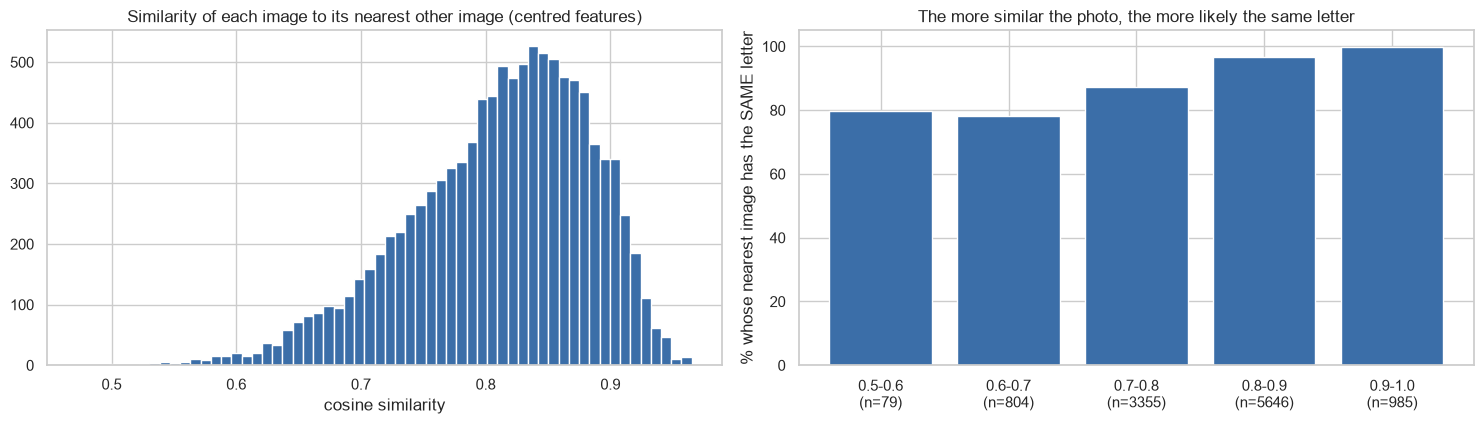

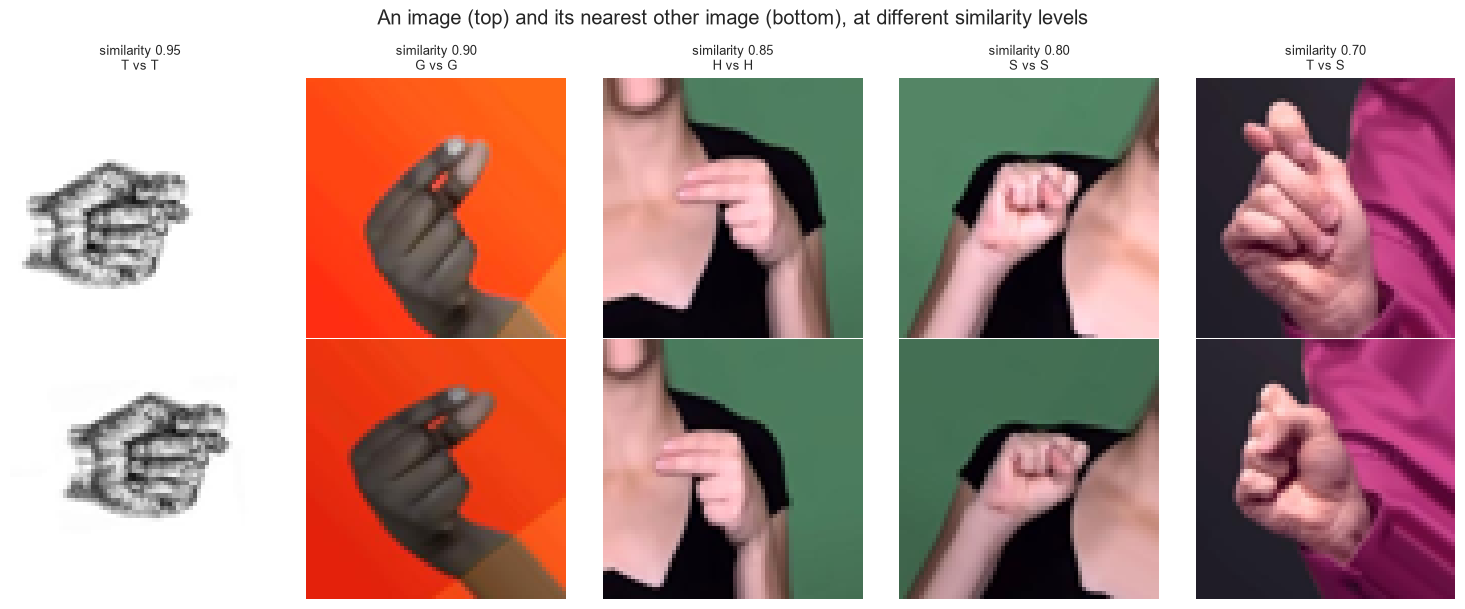

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].hist(sim, bins=60, color="#3b6ea8"); ax[0].set_title("Similarity of each image to its nearest other image (centred features)"); ax[0].set_xlabel("cosine similarity")
bins = [0.5, 0.6, 0.7, 0.8, 0.9, 1.01]; rate = [same_cls[(sim >= lo) & (sim < hi)].mean() * 100 for lo, hi in zip(bins[:-1], bins[1:])]; cnts = [((sim >= lo) & (sim < hi)).sum() for lo, hi in zip(bins[:-1], bins[1:])]
ax[1].bar([f"{lo:.1f}-{min(hi,1):.1f}\n(n={c})" for lo, hi, c in zip(bins[:-1], bins[1:], cnts)], rate, color="#3b6ea8"); ax[1].set_ylim(0, 105); ax[1].set_ylabel("% whose nearest image has the SAME letter"); ax[1].set_title("The more similar the photo, the more likely the same letter")
plt.tight_layout(); plt.show()
targets = [0.95, 0.9, 0.85, 0.8, 0.7]; fig, ax = plt.subplots(2, len(targets), figsize=(3 * len(targets), 6.2))
for k, tg in enumerate(targets):
    i = int(np.argmin(np.abs(sim - tg))); j = int(ind[i, 1]); ax[0, k].imshow(thumbs[i]); ax[1, k].imshow(thumbs[j]); ax[0, k].set_title(f"similarity {sim[i]:.2f}\n{LET[y[i]]} vs {LET[y[j]]}", fontsize=9)
    for r_ in (0, 1): ax[r_, k].axis("off")
plt.suptitle("An image (top) and its nearest other image (bottom), at different similarity levels"); plt.tight_layout(); plt.show()
n90, lab90 = groups_at(0.80)

**Reading it.**
* **The data are highly redundant.** After centring the features, the median image has a nearest neighbour with cosine similarity 0.82, and **92.5% of the time that neighbour shows the same letter**. In the second figure (an image on top, its closest other image below) similarity 0.95 and 0.90 are the same photograph shifted or recoloured, 0.85 and 0.80 are the same person, background and pose a moment later (a new frame or crop), and only at 0.70 do the pictures show different letters (T vs S).
* Counting images that have at least one such neighbour: **9% at similarity >= 0.90, 34% at >= 0.85 and 61% at >= 0.80.** At 0.80, 7% of the groups already contain more than one letter and at 0.70 it is 11%, so 0.80-0.85 is about the loosest definition of "the same shot" that is still mostly pure.
* (Technical note: with the raw ResNet features all images look 0.9+ similar because the features are all positive; the first version of this notebook used them and produced meaningless groups. Centring fixes it.)

## 5. How much does leakage inflate the score?
Logistic regression on the standardised embeddings. **Random 5-fold** (standard) vs **group 5-fold** (all near-copies of a photo stay on the same side), using the 0.80 groups; sensitivity to the threshold is shown too.

In [6]:
def lr(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=2000))
def cv_acc(splitter, groups=None, seed=0):
    accs = []; pred = np.zeros(len(y), int)
    for tr, te in splitter.split(E, y, groups):
        m = lr().fit(E[tr], y[tr]); p = m.predict(E[te]); pred[te] = p; accs.append(accuracy_score(y[te], p))
    return np.mean(accs), np.std(accs), pred
a_rand = cv_acc(StratifiedKFold(5, shuffle=True, random_state=0))
rows = [["random split (standard)", "-", a_rand[0] * 100, a_rand[1] * 100]]
for T in (0.75, 0.80, 0.90):
    n, lab = groups_at(T); r = cv_acc(GroupKFold(5), lab); rows.append([f"group split, similarity >= {T}", n, r[0] * 100, r[1] * 100])
leak = pd.DataFrame(rows, columns=["evaluation", "groups", "accuracy_%", "sd_over_folds"]); print(leak.round(1).to_string(index=False))

                     evaluation groups  accuracy_%  sd_over_folds
        random split (standard)      -        75.3            0.4
group split, similarity >= 0.75   3115        45.1            3.7
 group split, similarity >= 0.8   5586        58.3            2.3
 group split, similarity >= 0.9  10305        75.4            1.0


**Reading it.** The same logistic regression gives very different scores depending on how the data are split:
* random 5-fold (the usual way): **75.3%**;
* keeping near-copies together at similarity >= 0.90 (only the clear duplicates): 75.4%, no change;
* at >= 0.80 (same person/pose in neighbouring frames): **58.3%**;
* at >= 0.75: 45.1%, but here groups begin to merge different letters (see the 7-11% mixing rate), which makes the test unrealistically hard.
So **leakage worth roughly 17 points** comes from the near-identical shots between 0.80 and 0.90, not from exact duplicates. The honest estimate for "a new person, new background" lies between about 45% and 58%; I use the 0.80 split (58.3%) as the central figure. The random-split number would have reported a classifier that is 17 points better than it is for new signers. The quoted standard deviations (+/-0.4 to 3.7) are over the five folds only.

## 6. Pretrained features vs a CNN trained from scratch (same group split)
Fold 0 of the 0.80 group split. A small CNN is trained from scratch on 64x64 colour thumbnails (random crops and colour jitter as augmentation, no flips), against the logistic regression and a k-NN on ResNet features.

In [7]:
tr_i, te_i = next(GroupKFold(5).split(E, y, lab90)); print("train", len(tr_i), "| test", len(te_i), "| letters in test:", len(set(y[te_i])))
lr_m = lr().fit(E[tr_i], y[tr_i]); acc_lr = accuracy_score(y[te_i], lr_m.predict(E[te_i]))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(5, weights="distance")).fit(E[tr_i], y[tr_i]); acc_knn = accuracy_score(y[te_i], knn.predict(E[te_i]))
class Small(nn.Module):
    def __init__(self):
        super().__init__()
        self.b = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.h = nn.Sequential(nn.Dropout(.3), nn.Linear(128, 26))
    def forward(self, x): return self.h(self.b(x).flatten(1))
Xt = torch.from_numpy(thumbs).permute(0, 3, 1, 2).float() / 255; Yt = torch.from_numpy(y)
def aug(x):
    n = x.shape[0]; pad = F.pad(x, (4, 4, 4, 4), mode="replicate"); i, j = np.random.randint(0, 9, 2); x = pad[:, :, i:i + 64, j:j + 64]
    return (x * (0.8 + 0.4 * torch.rand(n, 1, 1, 1)) + 0.1 * (torch.rand(n, 3, 1, 1) - .5)).clamp(0, 1)
net_s = Small(); opt = torch.optim.AdamW(net_s.parameters(), 2e-3, weight_decay=1e-4); sched = torch.optim.lr_scheduler.OneCycleLR(opt, 4e-3, total_steps=14 * (len(tr_i) // 64 + 1))
hist = []
for ep in range(14):
    net_s.train(); p = torch.from_numpy(np.random.permutation(tr_i)); t0 = time.time()
    for k in range(0, len(p), 64):
        b = p[k:k + 64]; loss = F.cross_entropy(net_s(aug(Xt[b])), Yt[b]); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    net_s.eval()
    with torch.no_grad(): a_ = (net_s(Xt[te_i]).argmax(1) == Yt[te_i]).float().mean().item()
    hist.append(a_); print(f"  epoch {ep+1}: held-out-group accuracy {a_:.4f} ({time.time()-t0:.0f}s)")
acc_cnn = hist[-1]
res = pd.DataFrame({"accuracy_%": {"logistic regression on ResNet-18 features": acc_lr * 100, "k-NN (k=5) on ResNet-18 features": acc_knn * 100, "small CNN from scratch (64x64, last epoch)": acc_cnn * 100}}); print(res.round(1).to_string())

train 8698 | test 2175 | letters in test: 26


  epoch 1: held-out-group accuracy 0.0667 (88s)


  epoch 2: held-out-group accuracy 0.0497 (67s)


  epoch 3: held-out-group accuracy 0.0409 (85s)


  epoch 4: held-out-group accuracy 0.0359 (79s)


  epoch 5: held-out-group accuracy 0.1071 (79s)


... (5 outputs left out)

  epoch 11: held-out-group accuracy 0.3315 (62s)


  epoch 12: held-out-group accuracy 0.4639 (64s)


  epoch 13: held-out-group accuracy 0.4901 (75s)


  epoch 14: held-out-group accuracy 0.4897 (50s)
                                            accuracy_%
logistic regression on ResNet-18 features         56.8
k-NN (k=5) on ResNet-18 features                  65.1
small CNN from scratch (64x64, last epoch)        49.0


**Reading it (fold 0 of the 0.80 group split; 8,698 train / 2,175 test photos).**
* ResNet-18 features + **k-NN: 65.1%**, ResNet-18 features + logistic regression: 56.8% (this fold is a little easier than the 5-fold average of 58.3%), **small CNN from scratch: 49.0%** at the last epoch and still improving (14 epochs on 64 x 64 thumbnails, about 20 minutes on a CPU).
* Pretrained features beat the from-scratch network on this small, varied set, and k-NN beating logistic regression says that pictures resemble *specific* training pictures more than a smooth linear rule. Note that this fold keeps same-person shots together, but k-NN can still match a similar-looking person and background across groups.
* These are single-fold figures and the folds vary by +/-2-4 points; the ranking of LR vs CNN is clear (7-8 points), k-NN vs LR is probably real (8 points) but not guaranteed.
* These numbers cannot be compared with the reference's Sign-MNIST accuracy: that data set is a different, simpler setting (small cropped grey images), so a higher score there says nothing about this harder photo problem.

## 7. Which letters are confused? (group cross-validation predictions of the logistic regression)

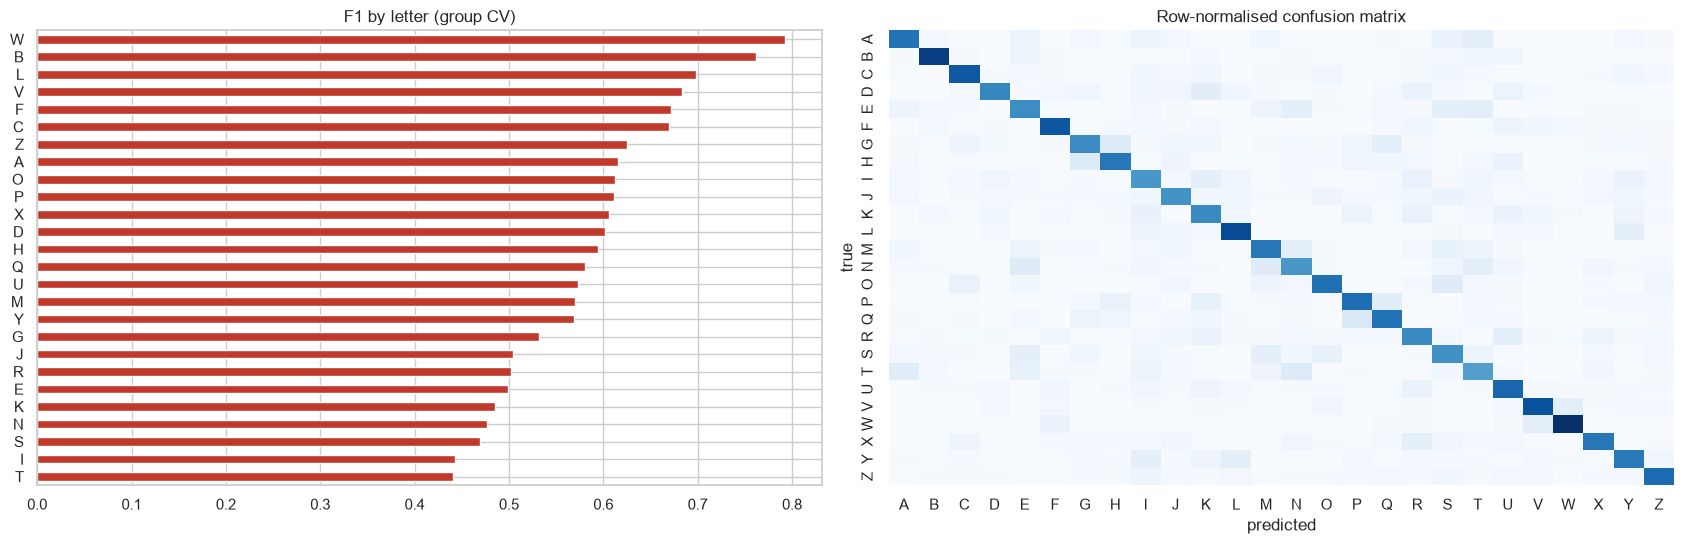

overall accuracy 58.3% | most frequent confusions (true -> predicted: count): ['Q->P: 45', 'T->N: 44', 'H->G: 43', 'G->H: 43', 'N->M: 41', 'N->E: 40', 'O->S: 39', 'T->A: 38']
lowest F1: {'T': 0.44, 'I': 0.44, 'S': 0.47, 'N': 0.48, 'K': 0.49} | J and Z (motion letters in real ASL): {'J': 0.5, 'Z': 0.63}


In [8]:
r90 = cv_acc(GroupKFold(5), lab90); pred = r90[2]
f1 = pd.Series(f1_score(y, pred, average=None), index=LET); cm = confusion_matrix(y, pred); off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], LET[i], LET[j]) for i in range(26) for j in range(26)], reverse=True)[:8]
fig, ax = plt.subplots(1, 2, figsize=(17, 5.6))
f1.sort_values().plot.barh(ax=ax[0], color=["#c0392b" if v < .8 else "#3b6ea8" for v in f1.sort_values()]); ax[0].set_title("F1 by letter (group CV)")
sns.heatmap(cm / cm.sum(1, keepdims=True), cmap="Blues", ax=ax[1], xticklabels=LET, yticklabels=LET, cbar=False); ax[1].set_title("Row-normalised confusion matrix"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.show()
print("overall accuracy %.1f%% | most frequent confusions (true -> predicted: count):" % (accuracy_score(y, pred) * 100), [f"{a}->{b}: {c}" for c, a, b in pairs])
print("lowest F1:", f1.sort_values().head(5).round(2).to_dict(), "| J and Z (motion letters in real ASL):", f1[["J", "Z"]].round(2).to_dict())

**Reading it (group cross-validation, logistic regression, overall 58.3%).**
* The weakest letters are T and I (F1 0.44), S (0.47), N (0.48) and K (0.49). The most frequent confusions are Q mistaken for P (45), T for N (44), H and G for each other (43 each), N for M (41) and E (40), O for S (39), T for A (38): fist-like letters (A, E, M, N, S, T) and the pairs G/H and P/Q differ only by thumb or finger position.
* J and Z, which are *motion* letters in real ASL, are not the worst (F1 0.50 and 0.63): here they are still frames labelled with the letter, so the model learns whatever static pose the photographers used; it cannot be a test of recognising the real signs.

## 8. Robustness: flips, rotation, brightness, blur
1,300 images from the held-out groups (50 per letter where available) are transformed and re-embedded with the model trained on the training groups only.

                             accuracy_%
transformation                         
original                           56.1
mirror (left-handed signer)        57.1
rotate 20 deg                      26.0
rotate 45 deg                      26.8
darker (x0.5)                      45.4
brighter (x1.6)                    30.2
blur (radius 4)                    19.8
centre crop 60%                    33.4
grayscale                          35.7


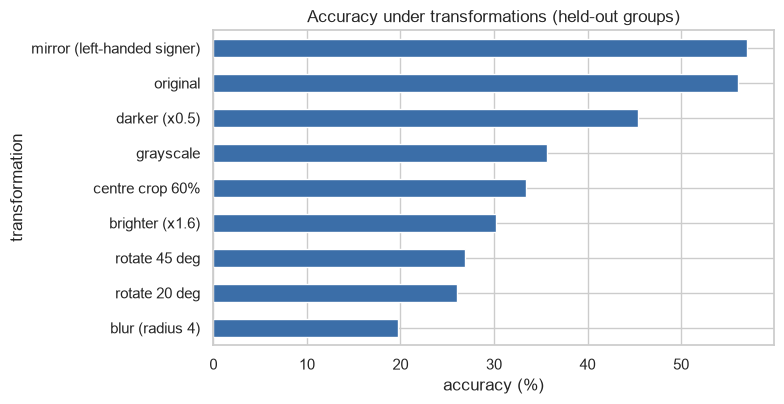

In [9]:
rs = np.random.RandomState(3); samp = np.concatenate([rs.choice(te_i[y[te_i] == c], min(50, (y[te_i] == c).sum()), replace=False) for c in range(26)])
T = {"original": lambda im: im, "mirror (left-handed signer)": lambda im: im.transpose(Image.FLIP_LEFT_RIGHT), "rotate 20 deg": lambda im: im.rotate(20, fillcolor=(128, 128, 128)), "rotate 45 deg": lambda im: im.rotate(45, fillcolor=(128, 128, 128)),
     "darker (x0.5)": lambda im: ImageEnhance.Brightness(im).enhance(.5), "brighter (x1.6)": lambda im: ImageEnhance.Brightness(im).enhance(1.6), "blur (radius 4)": lambda im: im.filter(ImageFilter.GaussianBlur(4)),
     "centre crop 60%": lambda im: im.crop((int(im.width * .2), int(im.height * .2), int(im.width * .8), int(im.height * .8))), "grayscale": lambda im: im.convert("L").convert("RGB")}
rows = []
for nm, f in T.items():
    Ez = embed([f(decode(i)) for i in samp]); rows.append([nm, accuracy_score(y[samp], lr_m.predict(Ez)) * 100])
rob = pd.DataFrame(rows, columns=["transformation", "accuracy_%"]).set_index("transformation"); print(rob.round(1).to_string())
ax = rob["accuracy_%"].sort_values().plot.barh(figsize=(8, 4.2), color="#3b6ea8"); ax.set_xlabel("accuracy (%)"); ax.set_title("Accuracy under transformations (held-out groups)"); plt.tight_layout(); plt.show()

**Reading it (about 1,300 held-out photos, original accuracy 56.1%).**
* **Mirror (left-handed signer): 57.1%**, no loss. The ResNet features appear to treat a mirrored hand much like the original, which is useful here (a left-handed signer is read about as well as a right-handed one), though some letters become ambiguous when mirrored; with so few photos per letter I cannot say which.
* Rotation by 20 or 45 degrees halves accuracy (26-27%); heavy blur (radius 4) drops it to 19.8%, brighter light to 30.2%, a 60% centre crop to 33.4%, darker light to 45.4%, grayscale to 35.7%.
* So the model is brittle outside the training conditions. A rotation or brightness augmentation during training and a crop-to-hand step before classification would be the first fixes; neither is tested here.

## 9. Save

In [10]:
final = lr().fit(E, y)
joblib.dump({"clf": final, "letters": LET}, "model/asl_logreg_resnet18.joblib")
torch.save(net_s.state_dict(), "model/asl_small_cnn.pt")
json.dump({"leakage": leak.set_index("evaluation")["accuracy_%"].round(1).to_dict(), "models_group_split": res["accuracy_%"].round(1).to_dict(), "robustness": rob["accuracy_%"].round(1).to_dict(),
           "note": "Features: torchvision ResNet-18 (ImageNet) penultimate layer, 224x224 resize, ImageNet normalisation."}, open("model/meta.json", "w"), indent=1)
print(os.listdir("model"))

['asl_logreg_resnet18.joblib', 'asl_small_cnn.pt', 'meta.json']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | Sign-MNIST (28 x 28 grey, separate signers in the test file) | 10,873 real colour photos, 26 letters, varied backgrounds |
| Model | small Keras network + augmentation | ResNet-18 features + logistic regression / k-NN, and a small CNN from scratch |
| Score | one accuracy | random split 75.3% vs **group split 58.3%** (range 45-75% by grouping rule) |
| Leakage | not examined | near-copies found: 34% of images have a neighbour with similarity >= 0.85; the gap is about 17 points |
| Errors | classification report | per-letter F1, confusions (fist letters, G/H, P/Q) |
| Robustness | not examined | mirror harmless; rotation, blur, lighting and cropping drop accuracy to 20-45% |

**What I learned.** (1) A classifier evaluated with a random split on photo data can report a score 17 points too high when near-identical shots exist. (2) Always look at the nearest neighbours of your images before you trust a number. (3) Pretrained features and a simple classifier beat a small CNN from scratch on a few thousand varied photos. (4) Check the embedding space before using it: raw positive features make every pair look similar.

**Limits.** The grouping rule is my own and the true "same photo" boundary is unknown (hence the range); one fold for the model comparison; the CNN was still improving; no hand detection or cropping; J and Z are static here. **Next step:** hand cropping with a detector (MediaPipe) before classification and a person-level split if signer IDs were available.